# 04. 취업 지원 Multi-Agent 자율 미션: 해설본

채용공고와 가상 지원자의 이력서를 분석해 역량 차이, 면접 준비, 취업 전략을 제안한다.  
이 Notebook은 미션의 한 가지 완성 예시이며, 위에서 아래로 독립 실행할 수 있다.

**학습 목표**

1. 전문 Agent의 책임과 State 입출력을 설명한다.
2. LLM의 도구 호출 요청과 Python 도구의 실제 실행을 구분한다.
3. 병렬 분석 결과를 합류시켜 최종 전략을 만든다.
4. 테스트 데이터로 근거 없는 경력 추정을 막고 결과를 검증한다.


## 1. Agent 설계와 전체 아키텍처

| Agent | 목표 | 입력 | 출력 | 도구 |
|---|---|---|---|---|
| Fit Analyst | 필수·우대 역량을 구분하고 보유 현황 계산 | 공고·이력서 | `fit_analysis`, `tool_trace` | `compare_skills` |
| Interview Coach | 이력서에 있는 프로젝트로 면접 질문과 답변 방향 제안 | 공고·이력서 | `interview_plan` | 없음 |
| Strategy Writer | 역량 차이와 면접 계획을 취업 전략으로 통합 | 앞선 두 결과 | `career_strategy` | 없음 |
| Review Agent | 계산 결과의 일관성과 미확인 경력 표시 점검 | 전체 결과 | `review_notes` | Python 검사 |

```mermaid
flowchart TD
  S[START] --> F[Fit Analyst]
  S --> I[Interview Coach]
  F --> W[Strategy Writer]
  I --> W
  W --> R[Review Agent]
  R --> E[END]
```

Fit Analyst와 Interview Coach는 같은 원본 데이터를 읽고 서로 다른 State Key에 쓴다.  
따라서 병렬 실행에 Reducer가 필요 없다.  
Writer는 두 결과가 모두 준비된 뒤 실행된다.


## 2. 라이브러리와 LLM 설정

`common.ai_model.get_llm_model()`으로 LLM 클라이언트를 초기화한다.  
`.env`의 `MODEL_BASE_URL`을 사용하며, 모델명은 `.env`의 `MODEL_ID` 값(기본값 `furiosa-ai/Qwen3-8B-FP8`)을 따른다.  
이 Notebook의 실행 셀은 실제 API 호출 비용이 발생한다.

In [18]:
import json
from typing import TypedDict

from IPython.display import Markdown, display
from langchain_core.messages import AIMessage, HumanMessage, ToolMessage
from langchain_core.tools import tool
from langgraph.graph import START, END, StateGraph

from common.ai_model import get_llm_model

llm = get_llm_model()
print(llm.model_name)


furiosa-ai/Qwen3-8B-FP8


## 3. 가상 채용공고와 지원자 이력서

원본 미션의 테스트 데이터를 그대로 사용한다.  
`required_skills`와 `preferred_skills`는 평가에서 별도로 취급한다.  
프로젝트 2회 경험을 근거 없이 실무 경력 연수로 바꾸지 않는다.


In [19]:
job_posting = {
    "title": "주니어 AI 개발자",
    "company": "가상 데이터서비스 기업",
    "responsibilities": ["Python 데이터 처리", "LLM API를 활용한 기능 개발", "평가 결과 기록"],
    "required_skills": ["Python", "SQL", "Git", "REST API"],
    "preferred_skills": ["LangGraph", "Docker", "클라우드 배포"],
}

candidate_resume = {
    "name": "가상 지원자 A",
    "projects": ["Python으로 문서 분류 모델 구현", "LangGraph 기반 챗봇 미니 프로젝트"],
    "skills": ["Python", "Git", "LangGraph"],
    "experience": "교육 과정 팀 프로젝트 2회",
}

test_input = {"job_posting": job_posting, "candidate_resume": candidate_resume}
print(job_posting["title"], "/", candidate_resume["name"])

주니어 AI 개발자 / 가상 지원자 A


## 4. 공통 State

State는 Agent 간 데이터 계약이다.  
각 Agent는 자신이 맡은 Key만 반환한다.  
`fit_analysis`는 수치와 목록을 담고, `tool_trace`는 모델의 요청과 도구의 응답을 보여 준다.


In [ ]:
import re

def strip_think(text: str) -> str:
    """Qwen3 같은 추론 모델이 답변 앞에 붙이는 <think>...</think> 블록을 제거한다."""
    return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()

In [21]:
class JobSupportState(TypedDict, total=False):
    job_posting: dict
    candidate_resume: dict
    fit_analysis: dict
    tool_trace: list
    interview_plan: str
    career_strategy: str
    review_notes: str


## 5. 역량 비교 도구

이 도구는 입력 목록끼리만 비교한다.  
대소문자와 양끝 공백을 정규화하되 원래 역량 이름을 결과에 남긴다.  
필수 역량 충족률은 채용 확률이나 종합 적합성 점수가 아니다.


In [22]:
def _normalize(skill: str) -> str:
    """대소문자와 양끝 공백 차이를 무시하고 역량 이름을 비교하기 위한 정규화."""
    return skill.strip().casefold()  # 다국어 비교에도 안전하도록 lower() 대신 casefold()를 쓴다.


def _split_by_ownership(skills: list[str], owned: set[str]) -> tuple[list[str], list[str]]:
    """역량 목록을 지원자가 보유한 것과 아닌 것으로 나눈다. 반환값의 이름은 원본 그대로다."""
    matched = [skill for skill in skills if _normalize(skill) in owned]
    missing = [skill for skill in skills if _normalize(skill) not in owned]
    return matched, missing


@tool
def compare_skills(
    required_skills: list[str],
    preferred_skills: list[str],
    candidate_skills: list[str],
) -> dict:
    """채용공고의 필수·우대 역량과 지원자 보유 역량을 비교한다."""
    owned = {_normalize(skill) for skill in candidate_skills}

    matched_required, missing_required = _split_by_ownership(required_skills, owned)
    matched_preferred, missing_preferred = _split_by_ownership(preferred_skills, owned)

    required_total = len(required_skills)
    # 필수 역량 목록이 비어 있으면 비율 자체가 무의미하므로 0이 아니라 None을 반환한다.
    required_match_rate = (
        round(len(matched_required) / required_total, 2) if required_total else None
    )

    return {
        "matched_required": matched_required,
        "missing_required": missing_required,
        "matched_preferred": matched_preferred,
        "missing_preferred": missing_preferred,
        "required_match_rate": required_match_rate,
    }


print(compare_skills.invoke({
    "required_skills": job_posting["required_skills"],
    "preferred_skills": job_posting["preferred_skills"],
    "candidate_skills": candidate_resume["skills"],
}))


{'matched_required': ['Python', 'Git'], 'missing_required': ['SQL', 'REST API'], 'matched_preferred': ['LangGraph'], 'missing_preferred': ['Docker', '클라우드 배포'], 'required_match_rate': 0.5}


In [23]:
result = compare_skills.invoke({
    "required_skills": job_posting["required_skills"],
    "preferred_skills": job_posting["preferred_skills"],
    "candidate_skills": candidate_resume["skills"],
})

In [24]:
print(result)

{'matched_required': ['Python', 'Git'], 'missing_required': ['SQL', 'REST API'], 'matched_preferred': ['LangGraph'], 'missing_preferred': ['Docker', '클라우드 배포'], 'required_match_rate': 0.5}


## 6. Fit Analyst의 Tool Calling

모델은 `compare_skills` 호출을 **요청**한다.  
도구는 그 요청을 받은 Python 코드가 **실행**한다.  
공고와 이력서의 구조화된 값은 원본 State를 신뢰하므로, 모델이 생성한 인수가 다르더라도 실제 계산에는 State 값을 사용한다.  
`ToolMessage`는 실행 결과를 호출 ID와 연결한다.  
계산 결과가 곧 이 Agent의 최종 출력이므로 모델을 다시 부르지 않는다.


In [25]:
def skill_tool_arguments(state: JobSupportState) -> dict:
    """도구에 전달할 값을 신뢰 가능한 원본 State에서 읽는다."""
    return {
        "required_skills": state["job_posting"]["required_skills"],
        "preferred_skills": state["job_posting"]["preferred_skills"],
        "candidate_skills": state["candidate_resume"]["skills"],
    }


def request_skill_tool(state: JobSupportState) -> AIMessage:
    """모델에 compare_skills 도구 호출을 요청한다."""
    arguments = skill_tool_arguments(state)
    prompt = (
        "채용공고와 지원자 보유 역량을 비교하라. compare_skills 도구를 호출하라. "
        "필수와 우대 역량을 구분하라.\n"
        f"입력: {json.dumps(arguments, ensure_ascii=False)}"
    )
    # 이 Agent는 compare_skills만 호출하면 되므로 tool_choice로 강제하고,
    # parallel_tool_calls=False로 호출이 정확히 하나만 오도록 만든다.
    skill_tool_llm = llm.bind_tools(
        [compare_skills], tool_choice="compare_skills", parallel_tool_calls=False
    )
    return skill_tool_llm.invoke([HumanMessage(content=prompt)])


In [26]:
def check_experience(state: JobSupportState) -> dict:
    """경력 요건이 있을 때 이력서만으로 충족 여부를 단정하지 않는다."""
    requirement = state["job_posting"].get("required_experience")
    if not requirement:
        return {"status": "요구 없음"}
    return {
        "required": requirement,
        "resume_evidence": state["candidate_resume"].get("experience", "기재 없음"),
        "status": "확인 필요",
    }


def _single_tool_call(request: AIMessage) -> dict:
    """compare_skills 호출이 정확히 하나인지 확인하고 그 호출 정보를 돌려준다."""
    calls = request.tool_calls
    if len(calls) != 1 or calls[0]["name"] != compare_skills.name:
        raise ValueError("compare_skills 도구 호출 요청이 필요하다.")
    return calls[0]


def fit_agent(state: JobSupportState) -> dict:
    """도구 호출 요청을 검증한 뒤, 신뢰 가능한 State 값으로 역량 비교를 실행한다."""
    request = request_skill_tool(state)
    call = _single_tool_call(request)

    # 핵심: 모델이 생성한 call["args"]를 그대로 쓰지 않는다.
    # AIMessage.tool_calls는 모델의 "실행 요청"일 뿐이고, 실제 계산은
    # 신뢰 가능한 원본 State에서 다시 만든 인수로 수행해야 한다.
    trusted_arguments = skill_tool_arguments(state)
    result = compare_skills.invoke(trusted_arguments)
    reply = ToolMessage(
        content=json.dumps(result, ensure_ascii=False),
        tool_call_id=call["id"],
        name=compare_skills.name,
    )

    fit_analysis = {
        **result,
        "experience_check": check_experience(state),
        # 모델이 생성한 인수와 실제로 실행에 쓴 인수가 달랐는지 기록해 Review 단계에서 확인한다.
        "model_arguments_match_state": call["args"] == trusted_arguments,
    }
    return {"fit_analysis": fit_analysis, "tool_trace": [request, reply]}


## 7. Interview Coach

면접 질문은 공고의 업무와 이력서에 적힌 프로젝트에서만 만든다.  
이 Agent는 Fit Analyst의 결과를 읽지 않으므로 동시에 실행할 수 있다.


In [27]:
def interview_agent(state: JobSupportState) -> dict:
    """검증 가능한 경험을 활용한 면접 준비 방향을 만든다."""
    posting = state["job_posting"]
    resume = state["candidate_resume"]
    prompt = (
        "당신은 면접 코치다. 공고 업무와 이력서의 실제 프로젝트에 근거해 "
        "면접 질문 3개와 답변 준비 방향을 Markdown으로 작성하라. "
        "이력서에 없는 실무 경력·성과는 만들지 마라.\n"
        f"공고: {json.dumps(posting, ensure_ascii=False)}\n"
        f"이력서: {json.dumps(resume, ensure_ascii=False)}"
    )
    return {"interview_plan": strip_think(llm.invoke(prompt).content)}


## 8. Strategy Writer

이 Agent가 두 병렬 결과를 모두 읽는 합류 지점이다.  
필수 역량 부족분을 우선하고 우대 역량은 별도로 제시한다.  
경력 요건이 추가된 경우에는 확인 필요 상태를 유지한다.


In [28]:
def strategy_agent(state: JobSupportState) -> dict:
    """역량 비교와 면접 계획을 근거 중심의 취업 전략으로 통합한다."""
    fit = state["fit_analysis"]
    interview = state["interview_plan"]
    prompt = (
        "당신은 취업 전략 작성자다. 직무 적합성, 필수 역량 보완, "
        "우대 역량, 면접 준비, 지원 전략을 짧은 Markdown으로 정리하라. "
        "필수 역량 충족률을 채용 확률로 해석하지 마라. 자료에 없는 경력·성과를 "
        "만들지 말고 확인 필요 항목을 명시하라.\n"
        f"역량 분석: {json.dumps(fit, ensure_ascii=False)}\n면접 계획: {interview}"
    )
    return {"career_strategy": strip_think(llm.invoke(prompt).content)}




## 9. Review Agent

여기서는 목록 계산의 일관성과 경력 확인 표시를 검사한다.  
자연어 전략의 모든 주장을 자동으로 사실 검증했다고 해석하면 안 된다.


In [29]:
def review_agent(state: JobSupportState) -> dict:
    """도구 결과의 일관성과 미확인 경력 표기를 점검한다."""
    fit = state["fit_analysis"]
    required = set(state["job_posting"]["required_skills"])
    matched = set(fit["matched_required"])
    missing = set(fit["missing_required"])
    issues = []
    # matched·missing이 겹치거나 둘을 합쳐도 required와 다르면 분류 로직 자체가 깨진 것이다.
    if matched & missing or matched | missing != required:
        issues.append("필수 역량 분류가 원본 공고와 일치하지 않는다.")
    if not fit["model_arguments_match_state"]:
        issues.append("모델의 도구 인수가 원본과 달라 State 값으로 계산했다.")
    if not state["interview_plan"] or not state["career_strategy"]:
        issues.append("면접 계획 또는 취업 전략이 비어 있다.")
    if fit["experience_check"]["status"] == "확인 필요":
        issues.append("경력 요건은 이력서만으로 충족 여부를 판단할 수 없다.")
    summary = "구조 검사 통과" if not issues else "\n".join(issues)
    return {"review_notes": summary + "\n자연어 주장과 원본 이력서는 사람이 최종 대조한다."}


## 10. Graph 구성과 Compile

`add_edge(START, ...)` 두 개가 병렬 분기를 만들고, `add_edge(["fit_agent", "interview_agent"], "strategy_agent")`가 두 결과의 완료를 기다린다.  
각 병렬 Agent가 다른 Key에 쓰므로 Reducer를 사용하지 않는다.


In [35]:
builder = StateGraph(JobSupportState)
builder.add_node("fit_agent", fit_agent)
builder.add_node("interview_agent", interview_agent)
builder.add_node("strategy_agent", strategy_agent)
builder.add_node("review_agent", review_agent)

# START에서 두 Edge를 내보내면 fit_agent와 interview_agent가 병렬로 실행된다.
builder.add_edge(START, "fit_agent")
builder.add_edge(START, "interview_agent")
# 출발 Node를 리스트로 주면 둘 다 끝난 뒤에만 strategy_agent가 실행된다(fan-in).
builder.add_edge(["fit_agent", "interview_agent"], "strategy_agent")
builder.add_edge("strategy_agent", "review_agent")
builder.add_edge("review_agent", END)

graph = builder.compile()


## 11. Graph 시각화

PNG 생성이 실패해도 Graph 실행은 계속할 수 있다.  
그때 Mermaid 텍스트를 확인한다.


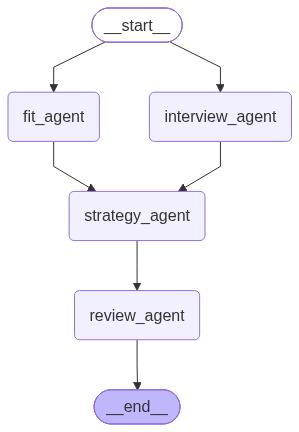

In [31]:
from IPython.display import Image

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())


## 12. 기본 입력 실행

`invoke`는 최종 State를 반환한다.  
도구 호출 요청, 면접 계획 작성, 전략 작성 단계에서 실제 API 요청이 발생한다.

In [32]:
result = graph.invoke(test_input)
fit = result["fit_analysis"]

print("필수 보유:", fit["matched_required"])
print("필수 부족:", fit["missing_required"])
print("우대 보유:", fit["matched_preferred"])
print("우대 부족:", fit["missing_preferred"])
print("경력 판단:", fit["experience_check"]["status"])
print("도구 요청:", result["tool_trace"][0].tool_calls)
print("도구 응답:", result["tool_trace"][1].content)


필수 보유: ['Python', 'Git']
필수 부족: ['SQL', 'REST API']
우대 보유: ['LangGraph']
우대 부족: ['Docker', '클라우드 배포']
경력 판단: 요구 없음
도구 요청: [{'name': 'compare_skills', 'args': {'required_skills': ['Python', 'SQL', 'Git', 'REST API'], 'preferred_skills': ['LangGraph', 'Docker', '클라우드 배포'], 'candidate_skills': ['Python', 'Git', 'LangGraph']}, 'id': 'call-f2c8c1038f8240419b1f9e2d0c515339', 'type': 'tool_call'}]
도구 응답: {"matched_required": ["Python", "Git"], "missing_required": ["SQL", "REST API"], "matched_preferred": ["LangGraph"], "missing_preferred": ["Docker", "클라우드 배포"], "required_match_rate": 0.5}


## 13. 취업 컨설팅 결과

계산된 역량 현황과 자연어 제안을 구분해서 읽는다.  
검토 의견은 자동 검사의 범위를 함께 적는다.


In [33]:
display(Markdown(result["career_strategy"]))
display(Markdown("### 검토 의견\n" + result["review_notes"]))

```markdown
# 취업 전략 요약

## 1. 역량 분석 및 보완 전략

### 필수 역량
- **충족된 역량**: Python, Git
- **미충족 역량**: SQL, REST API
  - **확인 필요**: SQL 및 REST API 관련 경력/성과 여부 확인 필요

### 우대 역량
- **충족된 역량**: LangGraph
- **미충족 역량**: Docker, 클라우드 배포
  - **확인 필요**: Docker 및 클라우드 배포 경험 여부 확인 필요

### 채용 확률 해석
- 필수 역량 충족률: 50% (SQL, REST API 미충족)
- **주의**: 필수 역량 충족률은 채용 확률과 직접적으로 연관되지 않음

## 2. 면접 준비 전략

### 면접 질문 및 답변 준비 방향

#### 1. 질문:  
**"당신이 Python으로 문서 분류 모델을 구현한 경험을 설명해 주세요. 이 과정에서 어떤 도구나 기술을 사용했고, 어떤 결과를 얻었나요?"**

- **답변 준비 방향**:
  - 프로젝트 개요: 목적, 데이터, 기대 효과
  - 기술 사용: Python, Git, SQL (필요 시)
  - 구체적 과정: 데이터 수집, 전처리, 모델 설계, 훈련, 평가
  - 성과: 정확도, 처리 속도, 팀 기여
  - 학습점: 기술적 성장, 문제 해결 경험

#### 2. 질문:  
**"LangGraph 기반 챗봇 미니 프로젝트에 대해 설명해 주세요. 이 프로젝트에서 어떤 역할을 했고, 어떤 기술을 활용했나요?"**

- **답변 준비 방향**:
  - 프로젝트 개요: 목적, 기능, 사용자 대상
  - 역할: 개발, 설계, 테스트 등 구체적 역할
  - 기술 활용: LangGraph, Python, REST API (필요 시)
  - 성과: 사용자 경험, 응답 속도, 팀 기여
  - 문제 해결: 발생한 문제와 해결 방법

#### 3. 질문:  
**"REST API를 활용한 기능 개발 경험은 있으신가요? 어떤 프로젝트에서 사용했고, 어떤 이점이 있었나요?"**

- **답변 준비 방향**:
  - 프로젝트 개요: 목적, 기능, 사용 목적
  - 기술 활용: Python, Git, SQL, REST API
  - 구체적 과정: API 설계, 개발, 테스트, 문서화
  - 성과: 시스템 통합, 사용자 접근성, 협업 효율성
  - 학습점: REST API 기반 개발 경험, 협업 능력

## 3. 지원 전략

- **필수 역량 보완**: SQL 및 REST API 관련 학습 및 실습 필요
- **우대 역능 보완**: Docker 및 클라우드 배포 관련 기술 습득 권장
- **지원 전략**: 기존 경력/성과에 기반한 강점 강조, 미충족 역량은 학습/경험 과정을 명확히 설명
- **면접 준비**: 기술적 성장, 문제 해결, 팀 협업 경험 강조
```

### 검토 의견
구조 검사 통과
자연어 주장과 원본 이력서는 사람이 최종 대조한다.

## 14. 테스트 시나리오와 실행 검증

기본 입력에서는 필수 역량 `SQL`, `REST API`가 부족하다.  
두 번째 입력은 필수 역량을 모두 가진 경우이고, 세 번째 입력은 공고에 경력 요건이 추가된 경우다.  
추가 API 비용을 피하기 위해 두 번째·세 번째 사례는 Graph 전체가 아니라 결정적 도구 함수(`compare_skills`, `check_experience`)로 직접 검증한다.

In [34]:
all_skills_resume = {**candidate_resume, "skills": job_posting["required_skills"]}
experience_job = {**job_posting, "required_experience": "관련 실무 3년 이상"}
test_cases = [
    ("기본", test_input),
    ("필수 역량 충족", {"job_posting": job_posting, "candidate_resume": all_skills_resume}),
    ("경력 요건 추가", {"job_posting": experience_job, "candidate_resume": candidate_resume}),
]

assert result["fit_analysis"]["missing_required"] == ["SQL", "REST API"]
assert result["fit_analysis"]["matched_preferred"] == ["LangGraph"]

# 두 번째·세 번째 사례는 graph.invoke를 다시 호출하지 않고 결정적 도구 함수로만 검증해
# 실제 API 호출을 추가로 늘리지 않는다.
exact_result = compare_skills.invoke(skill_tool_arguments(test_cases[1][1]))
assert exact_result["missing_required"] == []
assert check_experience(test_cases[2][1])["status"] == "확인 필요"

print("검증 통과:", [name for name, _ in test_cases])


검증 통과: ['기본', '필수 역량 충족', '경력 요건 추가']


## 15. 핵심 개념과 개선 방향

- **Tool Calling:** 모델의 `AIMessage.tool_calls`는 실행 요청이다.  
Python 도구 실행 뒤 `ToolMessage`로 결과를 연결했다.
- **병렬 협업:** Fit Analyst와 Interview Coach가 독립적으로 실행되고 Strategy Writer가 두 결과를 통합한다.
- **State 계약:** 각 Agent는 자신이 담당하는 Key만 갱신한다.
- **결과 해석:** 역량 목록의 충족률은 채용 가능성 점수가 아니며, 이력서에 없는 경력은 확인 필요로 남긴다.

확장하려면 근거 문장과 전략 문장을 연결하는 검토 기준을 추가하고, 지원자가 직접 결과를 수정·승인하는 단계를 설계할 수 있다.
